# Assignment Five - Stock Price Predictions
Aylie Lapierre Nagler, Anika Viado, Qlirim Teneqja, Arsi Kharghani<br>
COMP-3704 Neural Networks and Deep Learning<br>
November 12, 2026<br>

## Objective
To build a time sequence model for predicting short term future stock prices from historical data.

## Data
Historical stock price data on US-based stocks, last updated in 2017. The dataset is available at [Huge Stock Market Dataset | Kaggle](https://www.kaggle.com/datasets/borismarjanovic/price-volume-data-for-all-us-stocks-etfs) and is provided by Boris Marjanovic. A list of stock ticker symbols is available at [List of All Stock Ticker Symbols - Stock Analysis](https://stockanalysis.com/stocks/), to help identify the name of the stock from the txt file name.

## Problem Statement
An investment company is interested in learning about the potential profit in frequent buy/sell stock transactions. A time sequence model is developed to predict the price two days ahead based on recent prices. Four (or more) of the data files are used for training and a separate two for validation. Once the model is finalized, two other data files are used for testing to demonstrate how well the model makes predictions.

## Data Preparation

### <span style="color:royalblue">Import Libraries</span>

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow import keras
import random

### <span style="color:royalblue">Selecting the Data Files</span>

Our chosen stocks have a variety of date ranges starting as early as 1970 and as late as 2005. To ensure that all stocks are respresented equally we will take a slice of time that includes all stocks. We will use data starting on Nov 10 2007 up until the latest entries on Nov 10 2017.

In [32]:
train_files = ['lmt.us.txt', 'gs.us.txt', 'cost.us.txt', 'dal.us.txt']
val_files = ['aapl.us.txt', 'ko.us.txt']
test_files = ['nvda.us.txt', 'atvi.us.txt']

In [33]:
companies = {
    'lmt': 'Lockheed Martin',
    'gs': 'Goldman Sachs',
    'cost': 'Costco',
    'dal': 'Delta Air Lines',
    'aapl': 'Apple',
    'ko': 'Coca-Cola',
    'nvda': 'NVIDIA',
    'atvi': 'Activision Blizzard'
}


### <span style="color:royalblue">Closing Price Plots</span>

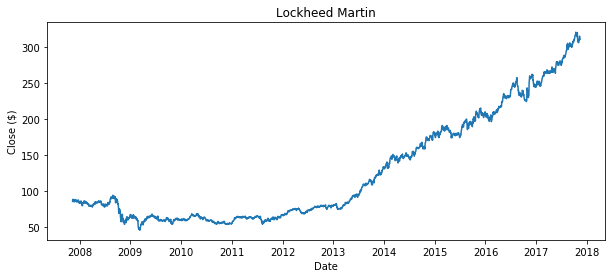

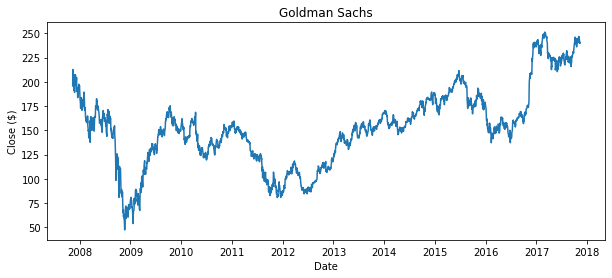

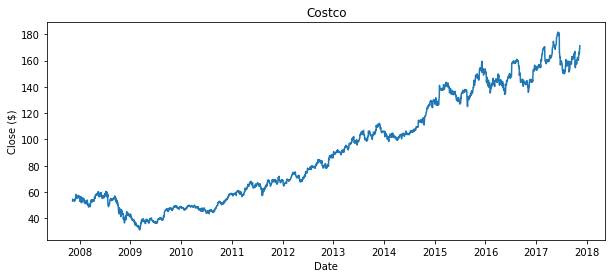

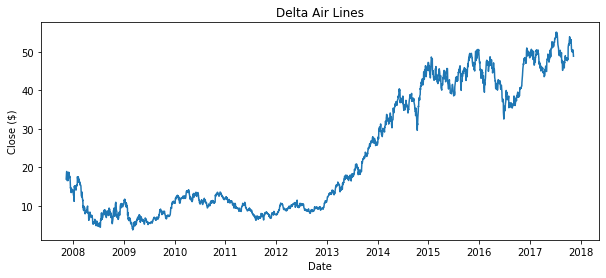

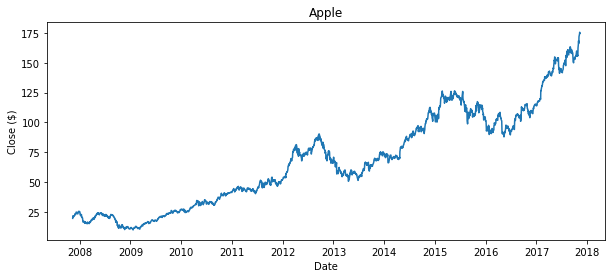

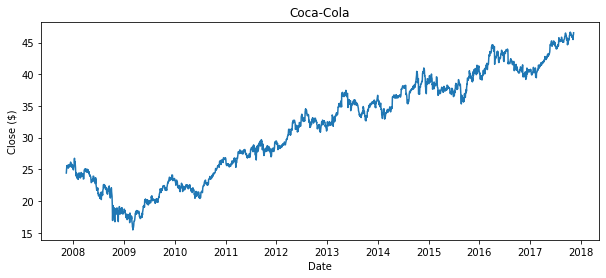

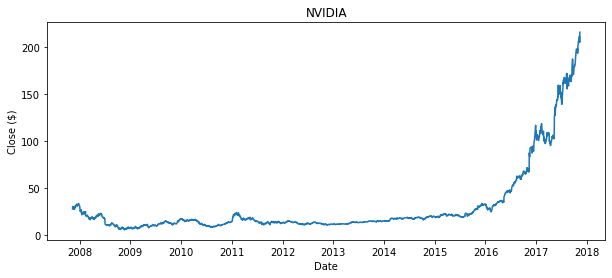

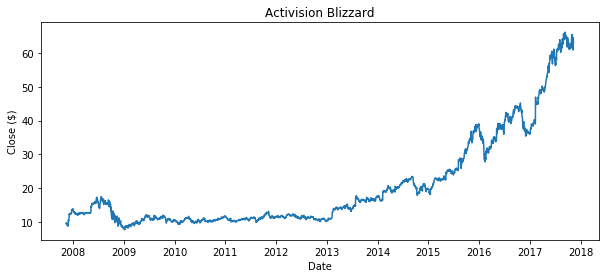

In [34]:
all_files = train_files + val_files + test_files

for f in all_files:
    df = pd.read_csv('../DATA/' + f, parse_dates=['Date'])
    df = df[df['Date'] >= '2007-11-10']
    
    ticker = f.split('.')[0]

    plt.figure(figsize=(10, 4))
    plt.plot(df['Date'], df['Close'])
    plt.title(companies[ticker])
    plt.xlabel('Date')
    plt.ylabel('Close ($)')
    plt.show()

### <span style="color:royalblue">Sequence Loading Function</span>

In [35]:
def get_lookback(file, look_back):
    df = pd.read_csv('../DATA/' + file, parse_dates=['Date'])
    df = df[df['Date'] >= '2007-11-10']

    y = df[['Close']].reset_index(drop=True)
    dataX = [y.shift(i) for i in range(look_back + 1, 1, -1)]
    dataX = pd.concat(dataX, axis=1)

    keep = dataX.notna().all(axis=1)
    return dataX[keep].values, y[keep].values

### <span style="color:royalblue">Loading and Concatenating the Data</span>

In [36]:
look_back = 10

def load_files(files, look_back):
    X_list = []
    y_list = []
    for file in files:
        X, y = get_lookback(file, look_back)
        X_list.append(X)
        y_list.append(y)
    return np.concatenate(X_list), np.concatenate(y_list)

X_train, y_train = load_files(train_files, look_back)
X_val, y_val = load_files(val_files, look_back)
X_test, y_test = load_files(test_files, look_back)

print('Train:', X_train.shape, y_train.shape)
print('Val:  ', X_val.shape, y_val.shape)
print('Test: ', X_test.shape, y_test.shape)

Train: (10032, 10) (10032, 1)
Val:   (5016, 10) (5016, 1)
Test:  (5015, 10) (5015, 1)


### <span style="color:royalblue">Scaling</span>

In [37]:
scaler = MinMaxScaler()
scaler.fit(y_train)

def scale(data):
    return scaler.transform(data.reshape(-1, 1)).reshape(data.shape)

X_train_scaled = scale(X_train)
y_train_scaled = scale(y_train)
X_val_scaled = scale(X_val)
y_val_scaled = scale(y_val)
X_test_scaled = scale(X_test)
y_test_scaled = scale(y_test)

## Modeling

### Shared Modeling Helpers

In [38]:
# Makes initialization and training more reproducible.
random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)


def prepare_model_inputs(X):
    """
    Convert 2D sequences (samples, lookback) to the 3D shape
    (samples, lookback, features) expected by Conv1D and SimpleRNN.
    """
    X = np.asarray(X, dtype=np.float32)

    if X.ndim != 2:
        raise ValueError(
            f"Expected X with shape (samples, lookback); got {X.shape}"
        )

    return X[..., np.newaxis]


def inverse_prices(values):
    """Convert values scaled by the training-fitted scaler back to dollars."""
    values = np.asarray(values)
    original_shape = values.shape
    return scaler.inverse_transform(values.reshape(-1, 1)).reshape(original_shape)


def train_model(model, X, y, epochs=20, batch_size=32, verbose=1):
    """
    Train without a validation split.

    Returns the Keras history, including the training loss recorded
    after each epoch.
    """
    X_model = prepare_model_inputs(X)
    y_model = np.asarray(y, dtype=np.float32).reshape(-1, 1)

    history = model.fit(
        X_model,
        y_model,
        epochs=epochs,
        batch_size=batch_size,
        validation_split=0.0,
        verbose=verbose,
    )
    return history


def evaluate(model, X, y_scaled):
    """
    Return predictions and metrics for a dataset.

    scaled_loss is the model's MSE in scaled units.
    mse_dollars and rmse_dollars use inverse-transformed prices.
    """
    X_model = prepare_model_inputs(X)
    y_scaled = np.asarray(y_scaled).reshape(-1, 1)

    scaled_loss = float(model.evaluate(X_model, y_scaled, verbose=0))
    predicted_scaled = model.predict(X_model, verbose=0)

    actual = inverse_prices(y_scaled).reshape(-1)
    predicted = inverse_prices(predicted_scaled).reshape(-1)

    mse = float(np.mean((actual - predicted) ** 2))
    rmse = float(np.sqrt(mse))

    return {
        "scaled_loss": scaled_loss,
        "mse_dollars": mse,
        "rmse_dollars": rmse,
        "actual": actual,
        "predicted": predicted,
    }


def plot_val(results, files, lookback, model_name="Model"):
    """
    Plot actual and predicted validation prices for each validation file.

    This assumes the files were concatenated in the same order as `files`
    using the notebook's get_lookback() function.
    """
    actual = results["actual"]
    predicted = results["predicted"]
    start = 0

    fig, axes = plt.subplots(
        len(files), 1, figsize=(12, 4 * len(files)), squeeze=False
    )

    for ax, file in zip(axes.flat, files):
        X_file, _ = get_lookback(file, lookback)
        end = start + len(X_file)

        ticker = file.split(".")[0]
        name = companies.get(ticker, ticker.upper())
        index = np.arange(len(X_file))

        ax.plot(index, actual[start:end], label="Actual", linewidth=1.5)
        ax.plot(index, predicted[start:end], label="Predicted", alpha=0.8)
        ax.set_title(f"{model_name}: {name} validation prices")
        ax.set_xlabel("Validation sequence index")
        ax.set_ylabel("Closing price ($)")
        ax.legend()
        ax.grid(alpha=0.25)

        start = end

    if start != len(actual):
        raise ValueError(
            "Validation file lengths do not match the evaluated arrays. "
            "Check the file order and lookback."
        )

    plt.tight_layout()
    plt.show()


### <span style="color:royalblue">Model 1</span>

Model 1 is the baseline time sequence model. A Conv1D layer extracts local patterns from each sequence of the closing prices, and a Simple RNN layer pr ocesses those patterns in the time order. Dropout is used during training to reduce overfitting. the final dense layer outputs one predicted closing price. 

The model is trained using MSE on prices scaled with the training-data scaler. Performance is also reported in dollars after reversing the scaling. 

In [39]:
model_1 = keras.Sequential([
    keras.layers.Input(shape=(look_back, 1)),
    keras.layers.Conv1D(
        filters=32,
        kernel_size=3,
        activation='relu'
    ),
    keras.layers.SimpleRNN(32),
    keras.layers.Dropout(0.20),
    keras.layers.Dense(1),
], name="Model_1_baseline")

model_1.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='mean_squared_error'
)

model_1.summary()

Model: "Model_1_baseline"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv1d_4 (Conv1D)            (None, 8, 32)             128       
_________________________________________________________________
simple_rnn_6 (SimpleRNN)     (None, 32)                2080      
_________________________________________________________________
dropout_4 (Dropout)          (None, 32)                0         
_________________________________________________________________
dense_4 (Dense)              (None, 1)                 33        
Total params: 2,241
Trainable params: 2,241
Non-trainable params: 0
_________________________________________________________________


#### <span style="color:cornflowerblue">Training Loss</span>

Train on 10032 samples
Epoch 1/20
10032/10032 [==============================] - 1s 125us/sample - loss: 0.0037
Epoch 2/20
10032/10032 [==============================] - 1s 73us/sample - loss: 0.00130s - loss: 0.0
Epoch 3/20
10032/10032 [==============================] - 1s 80us/sample - loss: 0.0011
Epoch 4/20
10032/10032 [==============================] - 1s 77us/sample - loss: 8.4784e-04
Epoch 5/20
10032/10032 [==============================] - 1s 75us/sample - loss: 7.5104e-04
Epoch 6/20
10032/10032 [==============================] - 1s 70us/sample - loss: 7.2897e-04
Epoch 7/20
10032/10032 [==============================] - 1s 76us/sample - loss: 6.4840e-04
Epoch 8/20
10032/10032 [==============================] - 1s 70us/sample - loss: 5.8534e-04
Epoch 9/20
10032/10032 [==============================] - 1s 73us/sample - loss: 5.2654e-04
Epoch 10/20
10032/10032 [==============================] - 1s 69us/sample - loss: 5.0670e-040s - loss
Epoch 11/20
10032/10032 [===================

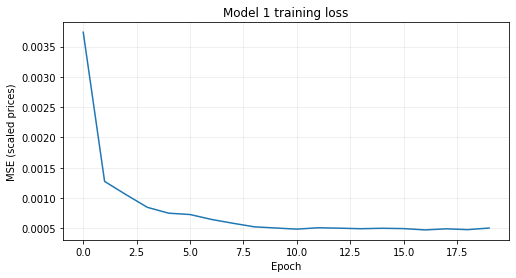

In [40]:
history_1 = train_model(
    model_1,
    X_train_scaled,
    y_train_scaled,
    epochs=20,
    batch_size=32,
)

train_results_1 = evaluate(model_1, X_train_scaled, y_train_scaled)

print(f"Final epoch training loss (scaled MSE): {history_1.history['loss'][-1]:.6f}")
print(f"Training MSE in dollars squared:        {train_results_1['mse_dollars']:.4f}")
print(f"Training RMSE in dollars:              ${train_results_1['rmse_dollars']:.2f}")

plt.figure(figsize=(8, 4))
plt.plot(history_1.history["loss"])
plt.title("Model 1 training loss")
plt.xlabel("Epoch")
plt.ylabel("MSE (scaled prices)")
plt.grid(alpha=0.25)
plt.show()

#### <span style="color:cornflowerblue">Validation Loss</span>

The trained model is evaluated on the two validation stocks, which were not used for fitting. RMSE is reported in dollars so that prediction errors are easier to interpret. these validation results can be compared with the other models before selecting one for the separate test set.

In [41]:
val_results_1 = evaluate(model_1, X_val_scaled, y_val_scaled)

print(f"Validation loss (scaled MSE):     {val_results_1['scaled_loss']:.6f}")
print(f"Validation MSE in dollars squared: {val_results_1['mse_dollars']:.4f}")
print(f"Validation RMSE in dollars:       ${val_results_1['rmse_dollars']:.2f}")

Validation loss (scaled MSE):     0.000034
Validation MSE in dollars squared: 3.4748
Validation RMSE in dollars:       $1.86


#### <span style="color:cornflowerblue">Validation Predictions</span>

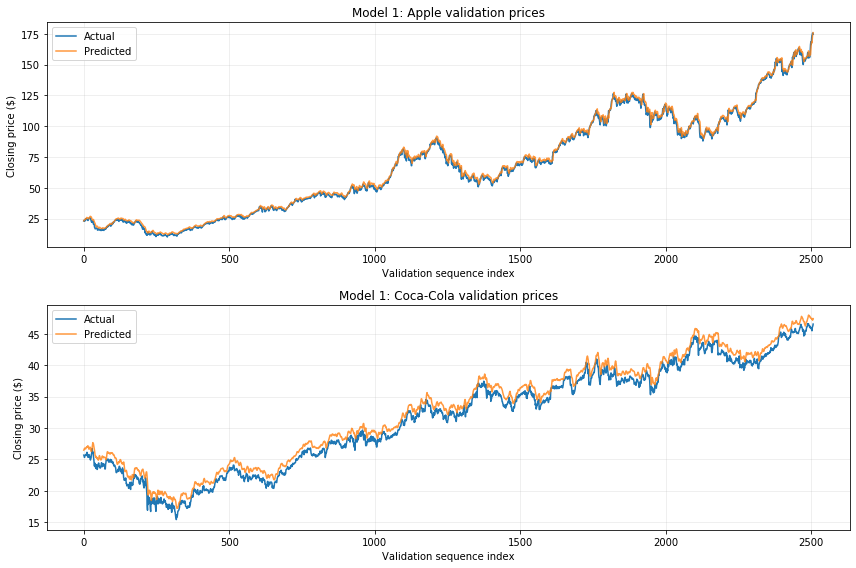

In [42]:
plot_val(
    val_results_1,
    val_files,
    look_back,
    model_name="Model 1",
)

### Model 1 Results

Model 1 was trained for **20 epochs**

| Metric | Training | Validation |
|---|---:|---:|
| MSE on scaled prices | 0.000090 | 0.000034 |
| MSE in dollars squared | 9.0741 | 3.4748 |
| RMSE in dollars | 3.01 | $1.86 |

the final training epoch recored a scaled MSE of **0.000506**. the training metrics in the table were recalculated after training, with dropout incactive, so they can be compared consistently with the validation metrics.


### <span style="color:royalblue">Model 2</span>

In Model 2 we only change the architecture. We use a Conv1D layer with 64 filters instead of 32, two Simple RNN layers are stacked (64 then 32 units).      
Dropout of 0.20, learning rate of 0.001, batch size of 32 and epochs of 20 stay the same as Model 1.

In [43]:
model_2 = keras.Sequential([
    keras.layers.Input(shape=(look_back, 1)),
    keras.layers.Conv1D(filters=64, kernel_size=3, activation='relu'),
    keras.layers.SimpleRNN(64, return_sequences=True),
    keras.layers.SimpleRNN(32),
    keras.layers.Dropout(0.20),
    keras.layers.Dense(1),
], name="Model_2")

model_2.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='mean_squared_error'
)
model_2.summary()

Model: "Model_2"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv1d_5 (Conv1D)            (None, 8, 64)             256       
_________________________________________________________________
simple_rnn_7 (SimpleRNN)     (None, 8, 64)             8256      
_________________________________________________________________
simple_rnn_8 (SimpleRNN)     (None, 32)                3104      
_________________________________________________________________
dropout_5 (Dropout)          (None, 32)                0         
_________________________________________________________________
dense_5 (Dense)              (None, 1)                 33        
Total params: 11,649
Trainable params: 11,649
Non-trainable params: 0
_________________________________________________________________


#### <span style="color:cornflowerblue">Training Loss</span>

Train on 10032 samples
Epoch 1/20
10032/10032 [==============================] - 2s 194us/sample - loss: 0.0056
Epoch 2/20
10032/10032 [==============================] - 1s 115us/sample - loss: 0.0016
Epoch 3/20
10032/10032 [==============================] - 1s 124us/sample - loss: 0.0014
Epoch 4/20
10032/10032 [==============================] - 1s 121us/sample - loss: 0.0011
Epoch 5/20
10032/10032 [==============================] - 1s 114us/sample - loss: 0.0011
Epoch 6/20
10032/10032 [==============================] - 1s 115us/sample - loss: 9.6058e-04
Epoch 7/20
10032/10032 [==============================] - 1s 115us/sample - loss: 8.2310e-04s - loss: 
Epoch 8/20
10032/10032 [==============================] - 1s 109us/sample - loss: 7.1547e-04
Epoch 9/20
10032/10032 [==============================] - 1s 121us/sample - loss: 6.6261e-04
Epoch 10/20
10032/10032 [==============================] - 1s 117us/sample - loss: 6.5238e-04
Epoch 11/20
10032/10032 [==============================]

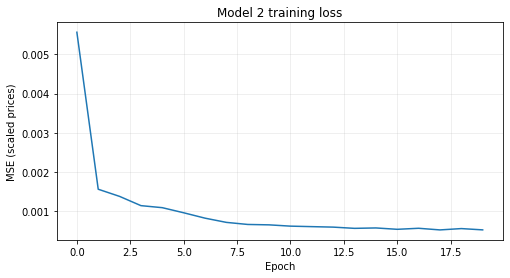

In [44]:
history_2 = train_model(model_2, X_train_scaled, y_train_scaled, epochs=20, batch_size=32)
train_results_2 = evaluate(model_2, X_train_scaled, y_train_scaled)

print(f"Final epoch training loss (scaled MSE): {history_2.history['loss'][-1]:.6f}")
print(f"Training MSE (scaled):                  {train_results_2['scaled_loss']:.6f}")
print(f"Training RMSE in dollars:              ${train_results_2['rmse_dollars']:.2f}")

plt.figure(figsize=(8, 4))
plt.plot(history_2.history["loss"])
plt.title("Model 2 training loss")
plt.xlabel("Epoch")
plt.ylabel("MSE (scaled prices)")
plt.grid(alpha=0.25)
plt.show()

#### <span style="color:cornflowerblue">Validation Loss</span>

In [45]:
val_results_2 = evaluate(model_2, X_val_scaled, y_val_scaled)

print(f"Validation loss (scaled MSE):      {val_results_2['scaled_loss']:.6f}")
print(f"Validation MSE in dollars squared: {val_results_2['mse_dollars']:.4f}")
print(f"Validation RMSE in dollars:       ${val_results_2['rmse_dollars']:.2f}")

Validation loss (scaled MSE):      0.000018
Validation MSE in dollars squared: 1.8230
Validation RMSE in dollars:       $1.35


#### <span style="color:cornflowerblue">Validation Predictions</span>

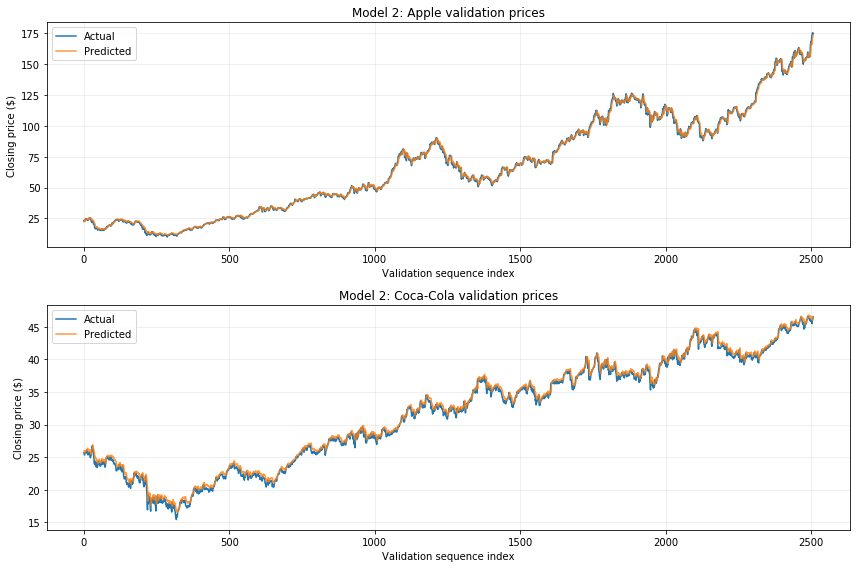

In [46]:
plot_val(
    val_results_2,
    val_files,
    look_back,
    model_name="Model 2",
)

#### Model 2 Results

| Metric | Training | Validation |
|---|---:|---:|
| MSE on scaled prices | 0.000072 | 0.000018 |
| MSE in dollars squared | 7.2846 | 1.8230 |
| RMSE in dollars | $2.70 | $1.35 |

In Model 2, validation MSE drops (3.47 &rarr; 1.82 dollars squared) and validation RMSE falls from $1.86 to $1.35.      
Training also improves (RMSE $3.01 &rarr; $2.70) with the majority of gain on validation.

#### What Changed

- **Conv1D filters:** 32 &rarr; 64
- **Simple RNN:** 1 layer (32 units) &rarr; 2 stacked layers (64 then 32 units)

#### Layers

- Conv1D (64 filters, kernel size 3, ReLU)
- SimpleRNN (64 units, returns sequences)
- SimpleRNN (32 units)
- Dropout (0.20)
- Dense (1)
- 11,649 parameters

### <span style="color:royalblue">Model 3</span>

#### <span style="color:cornflowerblue">Training Loss</span>

#### <span style="color:cornflowerblue">Validation Loss</span>

#### <span style="color:cornflowerblue">Validation Predictions</span>

### <span style="color:royalblue">Model Comparison</span>

#### <span style="color:cornflowerblue">Training and Validation Loss</span>

#### <span style="color:cornflowerblue">Predicted vs Actual Prices</span>

#### <span style="color:cornflowerblue">Best Model Selection</span>

### <span style="color:royalblue">Testing the Best Model</span>

#### <span style="color:cornflowerblue">Testing Loss</span>

#### <span style="color:cornflowerblue">Predictions vs True Values</span>

## Discussion

### <span style="color:royalblue">Best Model Selection</span>

#### <span style="color:cornflowerblue">Zooming In on Problem Areas</span>

#### <span style="color:cornflowerblue">Justification</span>

### <span style="color:royalblue">Predicting Two Days Ahead</span>

#### <span style="color:cornflowerblue">Estimated Prediction Error</span>

## References

## AI Statement